In [1]:
# This import is necessary to run the code cell-by-cell
try:
    from lab03_solution import *

    print("lab03_solution is being used")

except ImportError:
    from lab03 import *

    print("lab03 is being used")
import matplotlib.pyplot as plt

lab03_solution is being used


In [2]:
## The partial Fourier factor is 9/16.
PF = 9 / 16
op = Lab03_op(PF)
kdata = op.load_kdata_pf()
kdata_full = op.load_kdata_full()

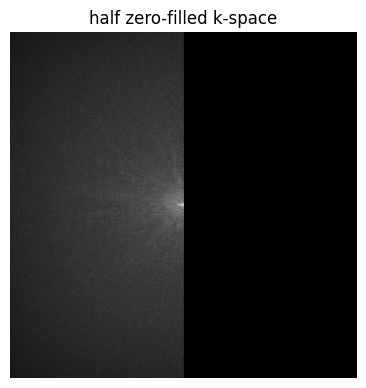

In [4]:
half_zf_kdata = op.get_half_zf_kdata(kdata)
utils.imshow([half_zf_kdata], norm=0.2, titles=["half zero-filled k-space"])

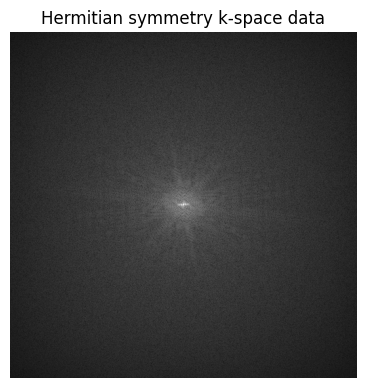

In [5]:
hm_kdata = op.hermitian_symmetry(half_zf_kdata)
utils.imshow([hm_kdata], norm=0.2, titles=["Hermitian symmetry k-space data"])

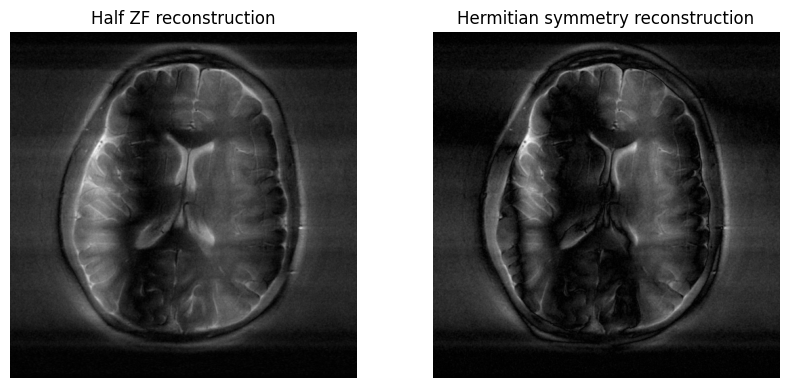

In [6]:
# Reconstruct half zero-filled k-space and Hermitian symmetric k-space data
half_zf_recon = utils.ifft2c(half_zf_kdata)
hm_recon = utils.ifft2c(hm_kdata)
utils.imshow([half_zf_recon, hm_recon], titles=["Half ZF reconstruction", "Hermitian symmetry reconstruction"])

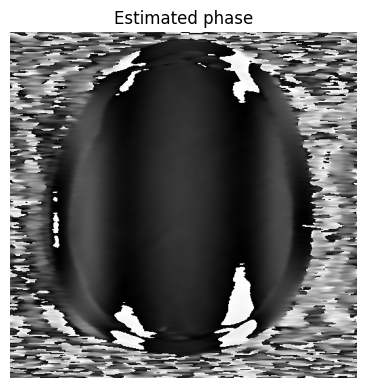

In [7]:
# Phase estimation image
est_phs = op.estim_phs(kdata)
utils.imshow([est_phs], titles=["Estimated phase"], is_mag=False)

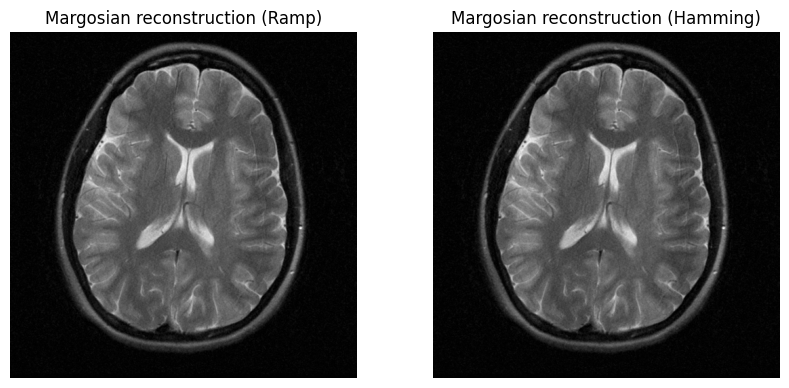

In [8]:
# Margosian reconstruction with different filters
margosian_ramp = op.pf_margosian(kdata, "ramp")
margosian_hamm = op.pf_margosian(kdata, "hamm")
utils.imshow([margosian_ramp, margosian_hamm], titles=["Margosian reconstruction (Ramp)", "Margosian reconstruction (Hamming)"])

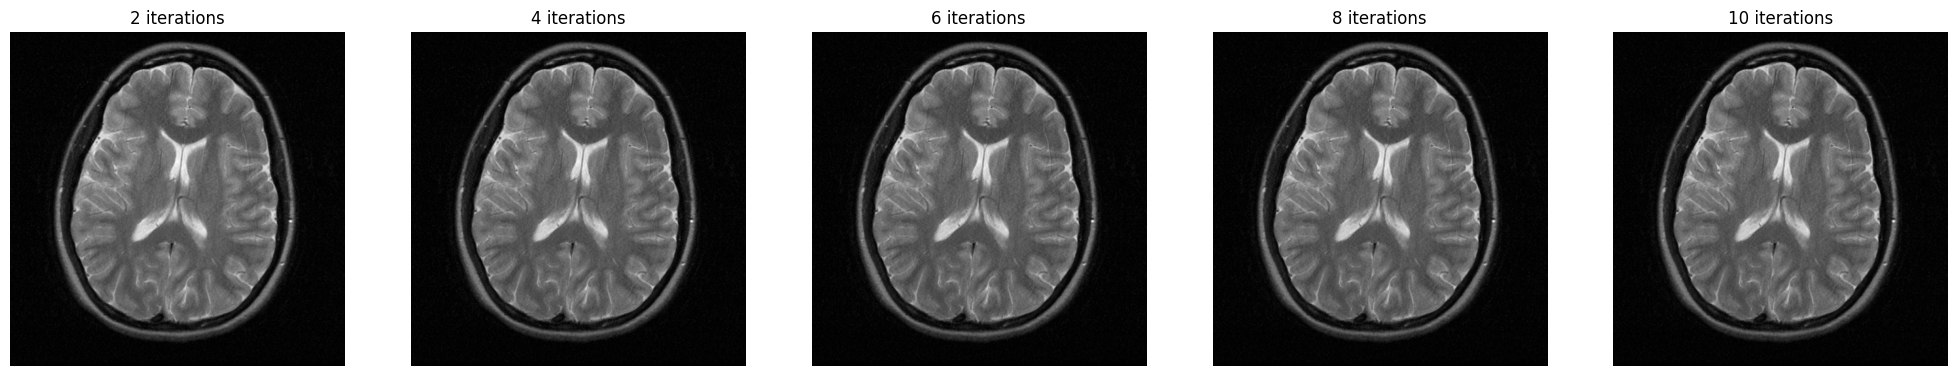

In [9]:
# POCS reconstruction
iterations = [2, 4, 6, 8, 10]
pocs_imgs = []
for i in iterations:
    pocs_imgs.append(op.pf_pocs(kdata, i))

utils.imshow(pocs_imgs, titles=[f"{i} iterations" for i in iterations])

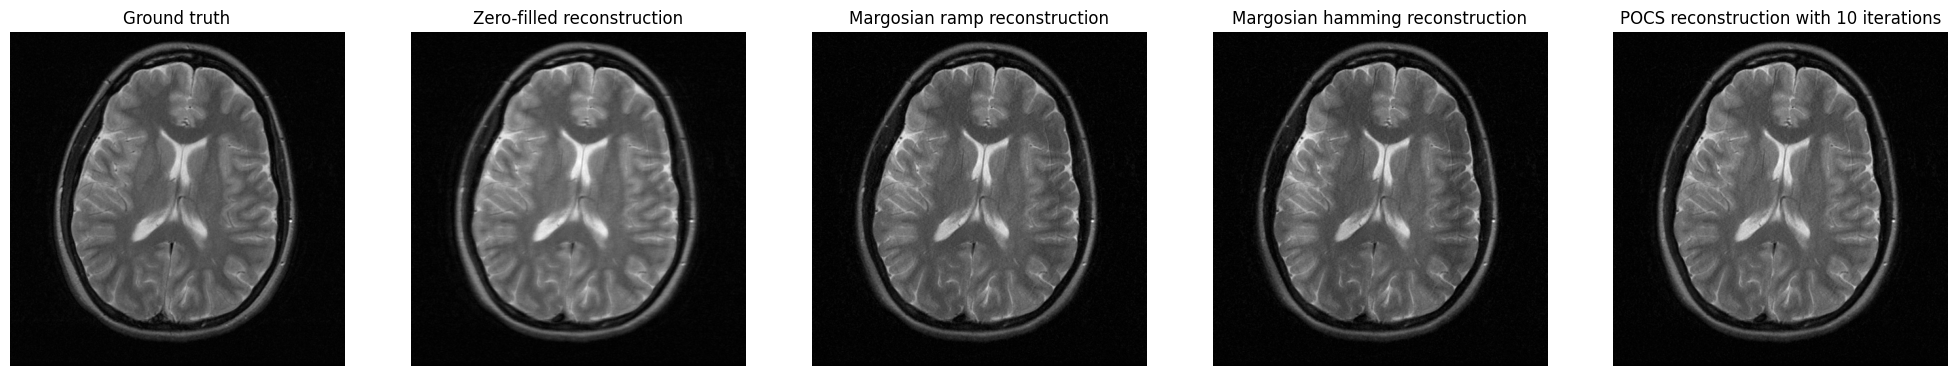

In [12]:
# Comparison of reconstruct
gt = utils.ifft2c(kdata_full)
zf_recon = utils.ifft2c(zf_kdata)
utils.imshow([gt, zf_recon, margosian_ramp, margosian_hamm, pocs_imgs[-1]], titles=["Ground truth", "Zero-filled reconstruction", "Margosian ramp reconstruction", "Margosian hamming reconstruction", f"POCS reconstruction with {iterations[-1]} iterations"])